# Visualização das métricas de kills

Comparação dos resultados salvos nos CSVs de `results/metrics/`. As métricas se referem ao conjunto de **validação**; menor MAE e RMSE indicam menor erro, enquanto maior R² indica melhor ajuste. A comparação geral usa validação; os resultados de teste disponíveis para o KNN, o HistGradientBoosting e o HistGradientBoosting com hiperparâmetros do PSO aparecem em seções separadas.

Execute as células em ordem após atualizar os CSVs. Dependências: `pandas` e `matplotlib` (incluídas em `requirements.txt`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

arquivos = {
    'baseline': 'baseline_kills.csv',
    'modelos': 'regressao_linear_kills.csv',
    'busca': 'regressao_linear_busca.csv',
    'coeficientes': 'regressao_linear_coeficientes.csv',
    'arvore': 'arvore_decisao_kills.csv',
    'busca_arvore': 'arvore_decisao_busca.csv',
    'importancias_arvore': 'arvore_decisao_importancias.csv',
    'knn': 'knn_kills.csv',
    'busca_knn': 'knn_busca.csv',
    'teste_knn': 'knn_teste.csv',
    'hgb': 'hist_gradient_boosting_kills.csv',
    'busca_hgb': 'hist_gradient_boosting_busca.csv',
    'teste_hgb': 'hist_gradient_boosting_teste.csv',
    'hgb_pso': 'hist_gradient_boosting_pso_kills.csv',
    'historico_pso': 'hist_gradient_boosting_pso_historico.csv',
    'teste_hgb_pso': 'hist_gradient_boosting_pso_teste.csv',
}

# Procura results/metrics a partir da pasta atual, para o notebook funcionar
# aberto na raiz do projeto ou dentro de notebooks/.
candidatos = (base / 'results' / 'metrics' for base in (Path.cwd(), *Path.cwd().parents))
pasta_metricas = next(
    (pasta for pasta in candidatos if all((pasta / nome).is_file() for nome in arquivos.values())),
    None,
)
if pasta_metricas is None:
    raise FileNotFoundError(
        'CSVs de métricas não encontrados em results/metrics. '
        'Gere-os com os comandos de reprodução do README.'
    )

dados = {chave: pd.read_csv(pasta_metricas / nome) for chave, nome in arquivos.items()}
display(pd.DataFrame({'arquivo': list(arquivos.values()), 'linhas': [len(dados[chave]) for chave in arquivos]}))

,arquivo,linhas
0,baseline_kills.csv,4
1,regressao_linear_kills.csv,2
2,regressao_linear_busca.csv,8
3,regressao_linear_coeficientes.csv,25
4,arvore_decisao_kills.csv,1
5,arvore_decisao_busca.csv,40
6,arvore_decisao_importancias.csv,25
7,knn_kills.csv,1
8,knn_busca.csv,39
9,knn_teste.csv,2


## Baseline

MAE, RMSE e R² das quatro regras de baseline no conjunto de validação. MAE e RMSE menores indicam menos erro; R² maior indica melhor ajuste. R² negativo significa desempenho pior que prever a média das kills na validação.

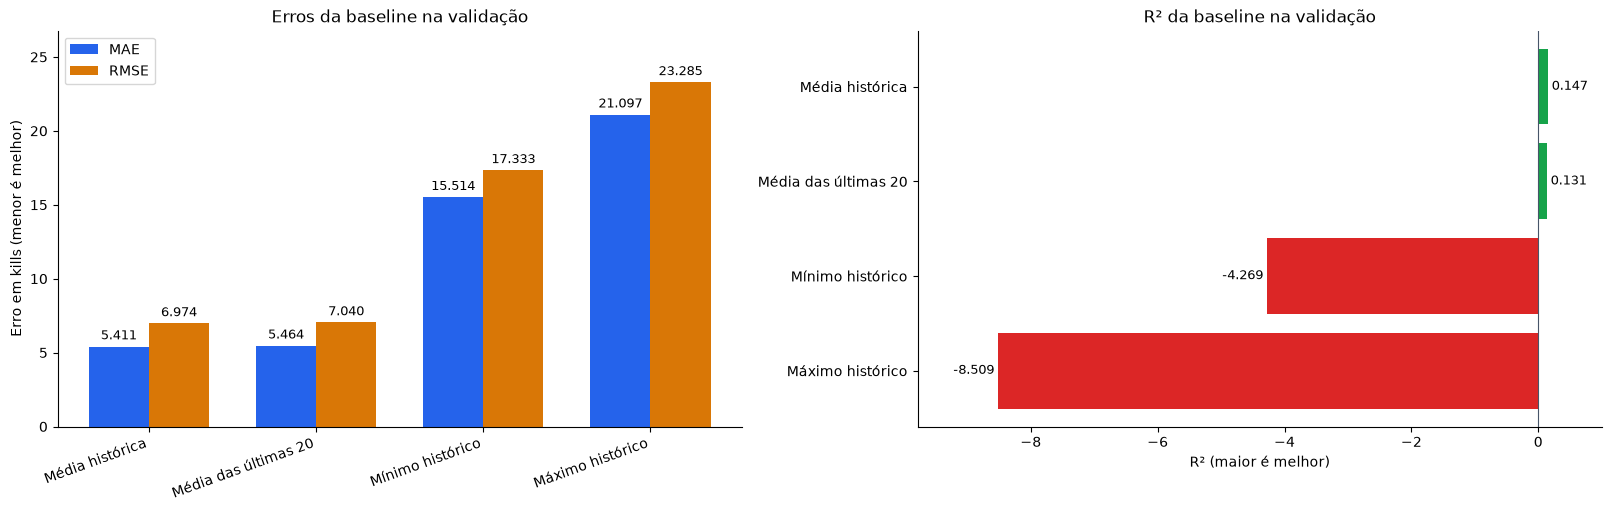

In [2]:
nomes_baseline = {
    'media': 'Média histórica',
    'media_20': 'Média das últimas 20',
    'minimo': 'Mínimo histórico',
    'maximo': 'Máximo histórico',
}
baseline_vis = dados['baseline'].query("conjunto == 'validacao'").copy()
baseline_vis['Regra'] = baseline_vis['regra'].map(nomes_baseline).fillna(baseline_vis['regra'])
posicoes = list(range(len(baseline_vis)))
largura = 0.36

fig, (eixo, eixo_r2) = plt.subplots(1, 2, figsize=(16, 5), layout='constrained')
barras_mae = eixo.bar([x - largura / 2 for x in posicoes], baseline_vis['MAE'], largura, label='MAE', color='#2563eb')
barras_rmse = eixo.bar([x + largura / 2 for x in posicoes], baseline_vis['RMSE'], largura, label='RMSE', color='#d97706')
eixo.set_xticks(posicoes, baseline_vis['Regra'], rotation=20, ha='right')
eixo.set_ylabel('Erro em kills (menor é melhor)')
eixo.set_title('Erros da baseline na validação')
eixo.set_ylim(0, baseline_vis[['MAE', 'RMSE']].to_numpy().max() * 1.15)
eixo.bar_label(barras_mae, fmt='%.3f', padding=3, fontsize=9)
eixo.bar_label(barras_rmse, fmt='%.3f', padding=3, fontsize=9)
eixo.legend()
eixo.spines[['top', 'right']].set_visible(False)

cores_r2 = ['#16a34a' if valor >= 0 else '#dc2626' for valor in baseline_vis['R2']]
barras_r2 = eixo_r2.barh(baseline_vis['Regra'], baseline_vis['R2'], color=cores_r2)
eixo_r2.invert_yaxis()
eixo_r2.axvline(0, color='#475569', linewidth=0.8)
eixo_r2.set_xlim(baseline_vis['R2'].min() * 1.15, max(1, baseline_vis['R2'].max() * 1.2))
eixo_r2.set_xlabel('R² (maior é melhor)')
eixo_r2.set_title('R² da baseline na validação')
eixo_r2.bar_label(barras_r2, fmt='%.3f', padding=3, fontsize=9)
eixo_r2.spines[['top', 'right']].set_visible(False)
plt.show()

## Comparação geral

MAE, RMSE e R² de todos os métodos nas mesmas partidas de validação. Menor MAE e RMSE e maior R² indicam previsões melhores. Todas as linhas devem ter MAE, RMSE, R² e a mesma quantidade de partidas. No gráfico de R² aparecem apenas as duas médias históricas entre as regras de baseline, pois mínimo e máximo têm valores negativos muito distantes dos demais. A tabela mantém todas as regras. Para o HistGradientBoosting aparece a melhor configuração de cada loss; a escolhida é a de menor MAE na validação (primeira linha de `hist_gradient_boosting_kills.csv`). A linha "HistGradientBoosting + PSO" usa os hiperparâmetros encontrados pelo PSO (issue #42).

In [3]:
nomes_modelos = {
    'regressao_linear': 'Regressão linear',
    'ridge': 'Ridge',
    'arvore_decisao': 'Árvore de decisão',
    'knn': 'KNN',
    'hist_gradient_boosting': 'HistGradientBoosting',
    'hist_gradient_boosting_pso': 'HistGradientBoosting + PSO',
}

baseline = dados['baseline'].query("conjunto == 'validacao'").copy()
modelos = pd.concat(
    [dados['modelos'], dados['arvore'], dados['knn'], dados['hgb'], dados['hgb_pso']],
    ignore_index=True,
)
modelos = modelos.query("conjunto == 'validacao'").copy()
baseline['Método'] = baseline['regra'].map(nomes_baseline).fillna(baseline['regra'])
modelos['Método'] = modelos['modelo'].map(nomes_modelos).fillna(modelos['modelo'])
# O HistGradientBoosting tem uma linha por loss; a loss entra no nome do método.
eh_hgb = modelos['modelo'].eq('hist_gradient_boosting')
modelos.loc[eh_hgb, 'Método'] = 'HistGradientBoosting (' + modelos.loc[eh_hgb, 'loss'] + ')'
metodos_modelos = set(modelos['Método'])

colunas = ['Método', 'partidas', 'MAE', 'RMSE', 'R2']
comparacao = (
    pd.concat([baseline[colunas], modelos[colunas]], ignore_index=True)
    .sort_values('MAE')
    .reset_index(drop=True)
)
if comparacao[['partidas', 'MAE', 'RMSE', 'R2']].isna().any().any():
    raise ValueError('A comparação de validação contém métricas ou quantidade de partidas ausentes.')
if comparacao['partidas'].nunique() != 1:
    raise ValueError('Os métodos foram avaliados em números diferentes de partidas.')
display(comparacao.round({'MAE': 3, 'RMSE': 3, 'R2': 3}))

referencia = baseline.loc[baseline['regra'].eq('media'), 'MAE'].iloc[0]
hgb_escolhido = dados['hgb'].nsmallest(1, 'MAE').iloc[0]
for codigo in [
    'regressao_linear', 'arvore_decisao', 'knn', 'hist_gradient_boosting',
    'hist_gradient_boosting_pso',
]:
    if codigo == 'hist_gradient_boosting':
        nome, mae_modelo = f"HistGradientBoosting ({hgb_escolhido['loss']})", hgb_escolhido['MAE']
    else:
        nome = nomes_modelos[codigo]
        mae_modelo = modelos.loc[modelos['modelo'].eq(codigo), 'MAE'].iloc[0]
    display(Markdown(
        f'**{nome} vs. média histórica:** MAE {mae_modelo:.3f} vs. {referencia:.3f} '
        f'({referencia - mae_modelo:.3f} kill a menos por partida, em média; '
        f'{(referencia - mae_modelo) / referencia:.1%} de redução).'
    ))

,Método,partidas,MAE,RMSE,R2
0,HistGradientBoosting + PSO,25916,5.356,6.933,0.157
1,HistGradientBoosting (absolute_error),25916,5.358,6.937,0.156
2,HistGradientBoosting (squared_error),25916,5.360,6.924,0.159
3,Regressão linear,25916,5.362,6.925,0.159
4,Ridge,25916,5.362,6.925,0.159
5,KNN,25916,5.377,6.935,0.156
6,Árvore de decisão,25916,5.393,6.963,0.150
7,Média histórica,25916,5.411,6.974,0.147
8,Média das últimas 20,25916,5.464,7.040,0.131
9,Mínimo histórico,25916,15.514,17.333,-4.269


**Regressão linear vs. média histórica:** MAE 5.362 vs. 5.411 (0.049 kill a menos por partida, em média; 0.9% de redução).

**Árvore de decisão vs. média histórica:** MAE 5.393 vs. 5.411 (0.018 kill a menos por partida, em média; 0.3% de redução).

**KNN vs. média histórica:** MAE 5.377 vs. 5.411 (0.034 kill a menos por partida, em média; 0.6% de redução).

**HistGradientBoosting (absolute_error) vs. média histórica:** MAE 5.358 vs. 5.411 (0.053 kill a menos por partida, em média; 1.0% de redução).

**HistGradientBoosting + PSO vs. média histórica:** MAE 5.356 vs. 5.411 (0.055 kill a menos por partida, em média; 1.0% de redução).

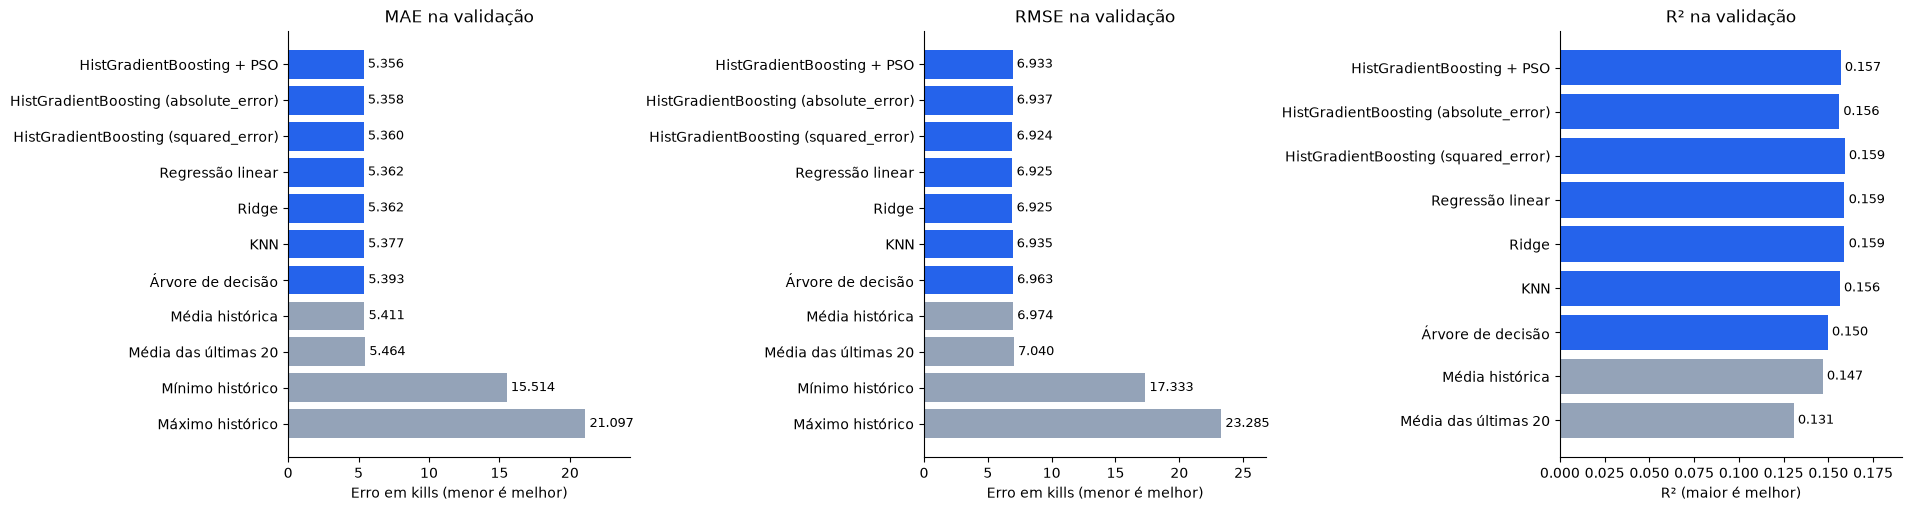

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(19, 5), layout='constrained')
for eixo, metrica in zip(eixos[:2], ['MAE', 'RMSE']):
    dados_grafico = comparacao
    cores = ['#2563eb' if metodo in metodos_modelos else '#94a3b8'
             for metodo in dados_grafico['Método']]
    barras = eixo.barh(dados_grafico['Método'], dados_grafico[metrica], color=cores)
    eixo.invert_yaxis()
    eixo.set_title(f'{metrica} na validação')
    eixo.set_xlabel('Erro em kills (menor é melhor)')
    eixo.set_xlim(0, comparacao[metrica].max() * 1.15)
    eixo.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
    eixo.spines[['top', 'right']].set_visible(False)

metodos_r2 = ['Média histórica', 'Média das últimas 20', *metodos_modelos]
dados_r2 = comparacao[comparacao['Método'].isin(metodos_r2)]
cores_r2 = ['#2563eb' if metodo in metodos_modelos else '#94a3b8'
            for metodo in dados_r2['Método']]
barras_r2 = eixos[2].barh(dados_r2['Método'], dados_r2['R2'], color=cores_r2)
eixos[2].invert_yaxis()
eixos[2].set_title('R² na validação')
eixos[2].set_xlabel('R² (maior é melhor)')
eixos[2].set_xlim(0, dados_r2['R2'].max() * 1.2)
eixos[2].bar_label(barras_r2, fmt='%.3f', padding=3, fontsize=9)
eixos[2].spines[['top', 'right']].set_visible(False)
plt.show()

## Busca de `alpha` para Ridge

A regressão linear sem regularização (`alpha = 0`) serve de referência. O gráfico amplia a escala vertical para mostrar diferenças pequenas de MAE.

,Configuração,MAE_treino,MAE_validacao,RMSE_validacao,R2_validacao
0,Linear,5.313331,5.362004,6.924526,0.159004
1,Ridge 0.01,5.313331,5.362004,6.924526,0.159004
2,Ridge 0.1,5.313331,5.362006,6.924527,0.159003
3,Ridge 1,5.313330,5.362024,6.924539,0.159000
4,Ridge 10,5.313331,5.362171,6.924643,0.158975
5,Ridge 100,5.313479,5.362684,6.925011,0.158886
6,Ridge 1000,5.314268,5.363300,6.925517,0.158763
7,Ridge 10000,5.316015,5.365787,6.927375,0.158311


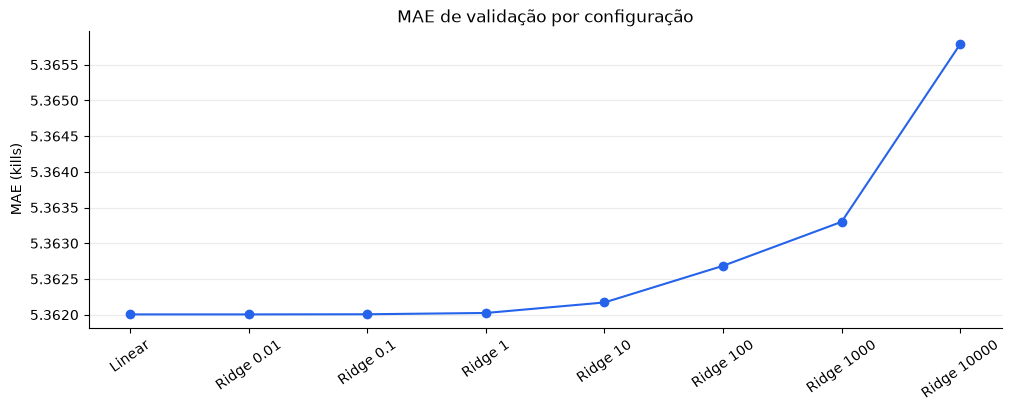

In [5]:
busca = dados['busca'].sort_values('alfa').copy()
busca['Configuração'] = busca.apply(
    lambda linha: 'Linear' if linha['modelo'] == 'regressao_linear' else f"Ridge {linha['alfa']:g}",
    axis=1,
)
display(busca[['Configuração', 'MAE_treino', 'MAE_validacao', 'RMSE_validacao', 'R2_validacao']])

fig, eixo = plt.subplots(figsize=(10, 4), layout='constrained')
eixo.plot(busca['Configuração'], busca['MAE_validacao'], marker='o', color='#2563eb')
eixo.set_title('MAE de validação por configuração')
eixo.set_ylabel('MAE (kills)')
eixo.tick_params(axis='x', rotation=35)
eixo.grid(axis='y', alpha=0.25)
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Importância das features da árvore

A importância indica a contribuição de cada feature para a redução do erro dentro da árvore treinada. Não representa causalidade nem o efeito isolado da feature.

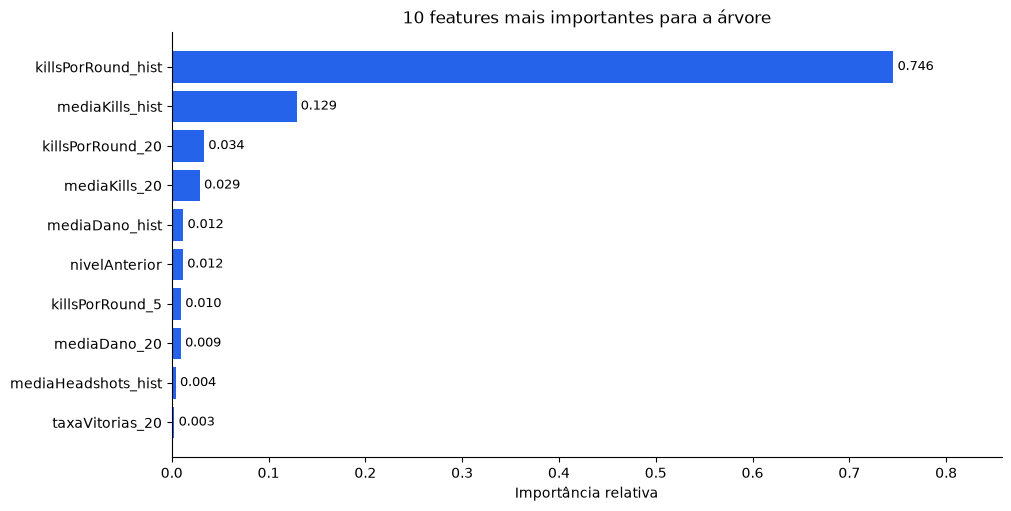

,feature,importancia
0,killsPorRound_hist,0.745516
1,mediaKills_hist,0.128930
2,killsPorRound_20,0.033515
3,mediaKills_20,0.029090
4,mediaDano_hist,0.011990
5,nivelAnterior,0.011724
6,killsPorRound_5,0.009701
7,mediaDano_20,0.009488
8,mediaHeadshots_hist,0.004258
9,taxaVitorias_20,0.002838


In [6]:
importancias = dados['importancias_arvore'].sort_values('importancia', ascending=False).copy()
principais_arvore = importancias.head(10).sort_values('importancia')

fig, eixo = plt.subplots(figsize=(10, 5), layout='constrained')
barras = eixo.barh(principais_arvore['feature'], principais_arvore['importancia'], color='#2563eb')
eixo.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
eixo.set_xlim(0, principais_arvore['importancia'].max() * 1.15)
eixo.set_xlabel('Importância relativa')
eixo.set_title('10 features mais importantes para a árvore')
eixo.spines[['top', 'right']].set_visible(False)
plt.show()
display(importancias)

## Busca de hiperparâmetros do HistGradientBoosting

Foram avaliadas 32 configurações para cada loss (`squared_error` e `absolute_error`), treinadas no treino e avaliadas na validação, com `random_state=42` e early stopping desligado. A configuração escolhida é a de menor MAE na validação; o conjunto de teste não participou da escolha. O gráfico mostra o MAE de cada configuração, ordenado dentro de cada loss.

,conjunto,modelo,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,partidas,MAE,RMSE,R2
0,validacao,hist_gradient_boosting,absolute_error,0.05,300,15,200,0.0,25916,5.357853,6.936792,0.156022
1,validacao,hist_gradient_boosting,squared_error,0.10,100,15,200,0.0,25916,5.360079,6.924010,0.159129


,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE_treino,MAE_validacao,RMSE_validacao,R2_validacao
0,absolute_error,0.05,300,15,200,0.0,5.225301,5.357853,6.936792,0.156022
1,absolute_error,0.05,100,15,200,0.0,5.274588,5.358342,6.934875,0.156488
2,absolute_error,0.10,100,15,200,0.0,5.249541,5.358545,6.938130,0.155696
3,absolute_error,0.05,100,15,200,1.0,5.274718,5.358637,6.934307,0.156626
4,absolute_error,0.05,100,31,200,1.0,5.240845,5.358886,6.936906,0.155994
5,absolute_error,0.05,100,31,200,0.0,5.241259,5.359527,6.936308,0.156139
6,absolute_error,0.10,100,15,200,1.0,5.248802,5.359660,6.938938,0.155499
7,absolute_error,0.10,100,31,200,1.0,5.190615,5.359732,6.939540,0.155353
8,absolute_error,0.05,300,15,20,1.0,5.226160,5.359952,6.938439,0.155621
9,absolute_error,0.10,100,15,20,1.0,5.249485,5.360041,6.937268,0.155906


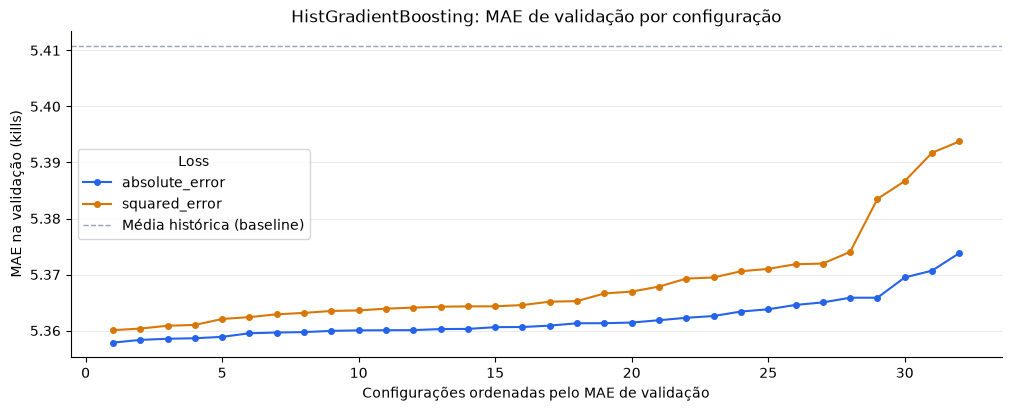

In [7]:
busca_hgb = dados['busca_hgb'].copy()
parametros_hgb = [
    'loss', 'learning_rate', 'max_iter', 'max_leaf_nodes', 'min_samples_leaf', 'l2_regularization',
]
if not dados['hgb']['partidas'].eq(comparacao['partidas'].iloc[0]).all():
    raise ValueError('O HistGradientBoosting usa partidas de validação diferentes dos demais métodos.')
display(dados['hgb'])
display(busca_hgb.sort_values('MAE_validacao').head(10)[
    parametros_hgb + ['MAE_treino', 'MAE_validacao', 'RMSE_validacao', 'R2_validacao']
])

fig, eixo = plt.subplots(figsize=(10, 4), layout='constrained')
cores_loss = {'squared_error': '#d97706', 'absolute_error': '#2563eb'}
for loss, grupo in busca_hgb.groupby('loss'):
    valores = grupo['MAE_validacao'].sort_values().to_numpy()
    eixo.plot(range(1, len(valores) + 1), valores, marker='o', markersize=4,
              color=cores_loss[loss], label=loss)
eixo.axhline(referencia, color='#94a3b8', linestyle='--', linewidth=1,
             label='Média histórica (baseline)')
eixo.set_xlabel('Configurações ordenadas pelo MAE de validação')
eixo.set_ylabel('MAE na validação (kills)')
eixo.set_title('HistGradientBoosting: MAE de validação por configuração')
eixo.grid(axis='y', alpha=0.25)
eixo.legend(title='Loss')
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## PSO para os hiperparâmetros do HistGradientBoosting

O PSO clássico (issue #42) buscou os hiperparâmetros num espaço contínuo, com 10 partículas, 10 iterações e as forças da literatura (`w=0.7298`, `c1=c2=1.49618`). O fitness é o MAE na validação. A iteração 0 é a população inicial, sorteada aleatoriamente. À esquerda, o MAE do `gbest` nunca aumenta e é comparado com o melhor da grid search; à direita, o MAE médio do enxame mostra se as partículas se concentraram perto da melhor posição. Detalhes em `docs/hist_gradient_boosting_pso.md`.

,iteracao,treinos,MAE_medio,MAE_gbest,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization
0,0,10,5.387846,5.357465,absolute_error,0.066445,260,9,86,1.366098
1,1,19,5.366630,5.356792,absolute_error,0.073221,192,9,277,1.380674
2,2,29,5.363028,5.356792,absolute_error,0.073221,192,9,277,1.380674
3,3,39,5.374584,5.355778,absolute_error,0.047094,201,9,293,1.579019
4,4,49,5.359033,5.355778,absolute_error,0.047094,201,9,293,1.579019
5,5,59,5.358795,5.355778,absolute_error,0.047094,201,9,293,1.579019
6,6,69,5.358158,5.355778,absolute_error,0.047094,201,9,293,1.579019
7,7,79,5.365090,5.355778,absolute_error,0.047094,201,9,293,1.579019
8,8,89,5.374231,5.355778,absolute_error,0.047094,201,9,293,1.579019
9,9,99,5.358182,5.355778,absolute_error,0.047094,201,9,293,1.579019


,Busca,treinos,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE,RMSE,R2
0,PSO,109,absolute_error,0.047094,201,9,293,1.579019,5.355778,6.933291,0.156873
1,Grid search,64,absolute_error,0.050000,300,15,200,0.000000,5.357853,6.936792,0.156022


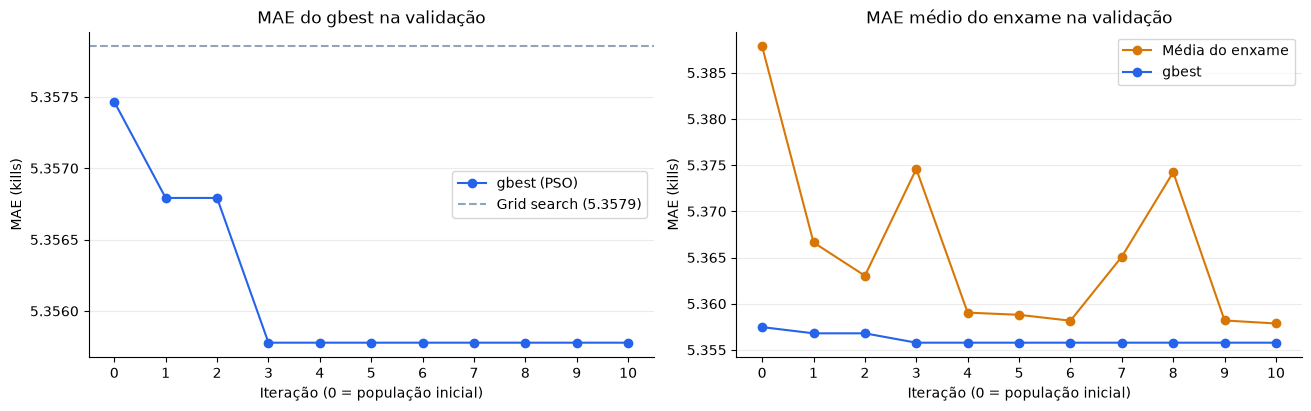

**Convergência:** o MAE do gbest foi de 5.3575 na população inicial para 5.3558 na iteração 10. Diferença para a grid search: 0.0021 kill (0.04%).

In [8]:
historico_pso = dados['historico_pso']
pso = dados['hgb_pso'].iloc[0]
grid = dados['hgb'].nsmallest(1, 'MAE').iloc[0]
display(historico_pso)

comparacao_busca = pd.DataFrame([
    {'Busca': 'PSO', 'treinos': historico_pso['treinos'].iloc[-1],
     **pso[parametros_hgb], **pso[['MAE', 'RMSE', 'R2']]},
    {'Busca': 'Grid search', 'treinos': len(dados['busca_hgb']),
     **grid[parametros_hgb], **grid[['MAE', 'RMSE', 'R2']]},
])
display(comparacao_busca)

fig, (eixo_gbest, eixo_enxame) = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
iteracoes = historico_pso['iteracao']
eixo_gbest.plot(iteracoes, historico_pso['MAE_gbest'], marker='o', color='#2563eb', label='gbest (PSO)')
eixo_gbest.axhline(grid['MAE'], color='#94a3b8', linestyle='--', label=f"Grid search ({grid['MAE']:.4f})")
eixo_gbest.set_title('MAE do gbest na validação')
eixo_enxame.plot(iteracoes, historico_pso['MAE_medio'], marker='o', color='#d97706', label='Média do enxame')
eixo_enxame.plot(iteracoes, historico_pso['MAE_gbest'], marker='o', color='#2563eb', label='gbest')
eixo_enxame.set_title('MAE médio do enxame na validação')
for eixo in (eixo_gbest, eixo_enxame):
    eixo.set_xlabel('Iteração (0 = população inicial)')
    eixo.set_ylabel('MAE (kills)')
    eixo.set_xticks(iteracoes)
    eixo.grid(axis='y', alpha=0.25)
    eixo.legend()
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

inicial, final = historico_pso['MAE_gbest'].iloc[0], historico_pso['MAE_gbest'].iloc[-1]
display(Markdown(
    f'**Convergência:** o MAE do gbest foi de {inicial:.4f} na população inicial para {final:.4f} '
    f"na iteração {iteracoes.iloc[-1]}. Diferença para a grid search: {grid['MAE'] - final:.4f} kill "
    f'({(grid["MAE"] - final) / grid["MAE"]:.2%}).'
))

## Busca de vizinhos e distância para o KNN

Cada linha mostra o MAE na validação para uma combinação de `K` e distância. Menor MAE é melhor; o conjunto de teste não participou da escolha.

,k,distancia,MAE_validacao,RMSE_validacao,R2_validacao
0,300,manhattan,5.377264,6.935334,0.156376
1,200,manhattan,5.380677,6.940995,0.154998
2,300,euclidean,5.381383,6.941531,0.154868
3,200,euclidean,5.386161,6.946005,0.153778
4,100,manhattan,5.393125,6.955888,0.151368
5,100,euclidean,5.401084,6.962751,0.149693
6,200,chebyshev,5.422990,6.985479,0.144133
7,50,manhattan,5.423496,6.991853,0.142570
8,300,chebyshev,5.425169,6.984803,0.144298
9,100,chebyshev,5.428265,6.992652,0.142374


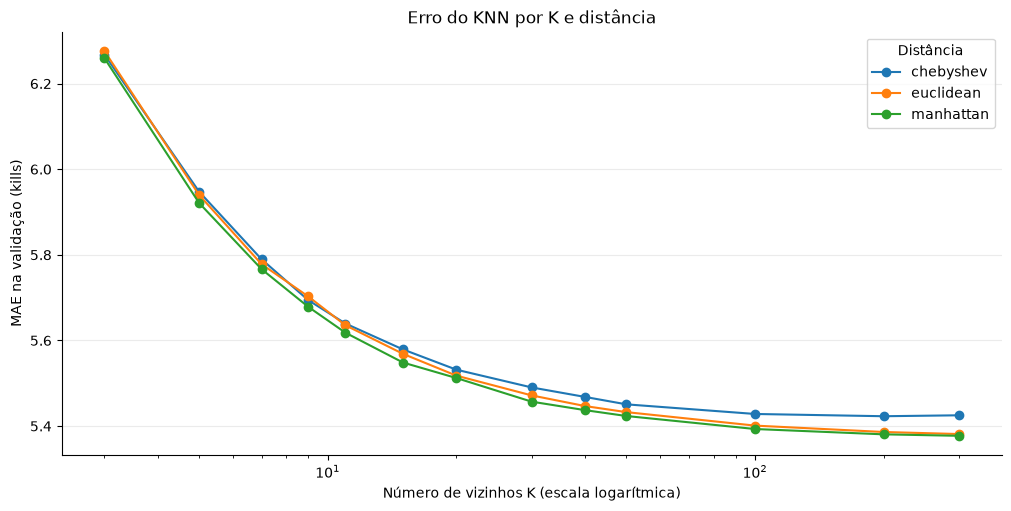

In [9]:
busca_knn = dados['busca_knn'].sort_values(['distancia', 'k'])
display(busca_knn.sort_values('MAE_validacao').head(10))

fig, eixo = plt.subplots(figsize=(10, 5), layout='constrained')
for distancia, grupo in busca_knn.groupby('distancia'):
    eixo.plot(grupo['k'], grupo['MAE_validacao'], marker='o', label=distancia)
eixo.set_xscale('log')
eixo.set_xlabel('Número de vizinhos K (escala logarítmica)')
eixo.set_ylabel('MAE na validação (kills)')
eixo.set_title('Erro do KNN por K e distância')
eixo.grid(axis='y', alpha=0.25)
eixo.legend(title='Distância')
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Resultado do KNN no teste

O teste foi usado após a escolha de `K = 300` e distância Manhattan na validação. Esta comparação inclui apenas KNN e sua baseline avaliados no teste; não deve ser misturada com a comparação geral de validação.

,conjunto,modelo,k,distancia,partidas,MAE,RMSE,R2
0,teste,baseline_media,NaN,NaN,25916,5.412317,7.030461,0.128914
1,teste,knn,300.0,manhattan,25916,5.369530,6.973711,0.142920


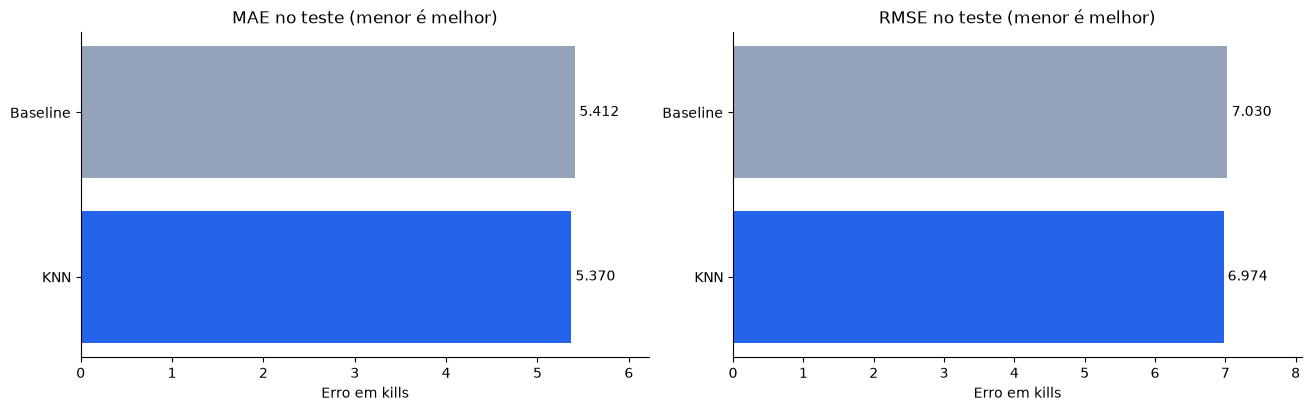

**KNN vs. baseline no teste:** redução de 0.043 kill no MAE (0.8%).

In [10]:
teste_knn = dados['teste_knn']
display(teste_knn)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
rotulos_teste = teste_knn['modelo'].map({'baseline_media': 'Baseline', 'knn': 'KNN'})
for eixo, metrica in zip(eixos, ['MAE', 'RMSE']):
    barras = eixo.barh(rotulos_teste, teste_knn[metrica], color=['#94a3b8', '#2563eb'])
    eixo.invert_yaxis()
    eixo.bar_label(barras, fmt='%.3f', padding=3)
    eixo.set_xlim(0, teste_knn[metrica].max() * 1.15)
    eixo.set_title(f'{metrica} no teste (menor é melhor)')
    eixo.set_xlabel('Erro em kills')
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

mae_baseline_teste = teste_knn.loc[teste_knn['modelo'].eq('baseline_media'), 'MAE'].iloc[0]
mae_knn_teste = teste_knn.loc[teste_knn['modelo'].eq('knn'), 'MAE'].iloc[0]
display(Markdown(
    f'**KNN vs. baseline no teste:** redução de {mae_baseline_teste - mae_knn_teste:.3f} '
    f'kill no MAE ({(mae_baseline_teste - mae_knn_teste) / mae_baseline_teste:.1%}).'
))

## Resultado do HistGradientBoosting no teste

O teste foi usado só depois da escolha da configuração na validação (`loss="absolute_error"`, `learning_rate=0.05`, `max_iter=300`, `max_leaf_nodes=15`, `min_samples_leaf=200`, `l2_regularization=0`). O modelo foi treinado apenas no treino, como na busca e no KNN. A baseline é a média histórica de kills nas mesmas partidas de teste, e o KNN aparece como referência por ter sido avaliado no mesmo conjunto. Assim como na seção do KNN, estes números não devem ser misturados com a comparação geral de validação.

,conjunto,modelo,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,partidas,MAE,RMSE,R2
0,teste,baseline_media,NaN,NaN,NaN,NaN,NaN,NaN,25916,5.412317,7.030461,0.128914
1,teste,hist_gradient_boosting,absolute_error,0.05,300.0,15.0,200.0,0.0,25916,5.367792,6.991659,0.138503


,Método,MAE,RMSE,R2
0,Baseline,5.412,7.030,0.129
1,KNN,5.370,6.974,0.143
2,HistGradientBoosting (absolute_error),5.368,6.992,0.139


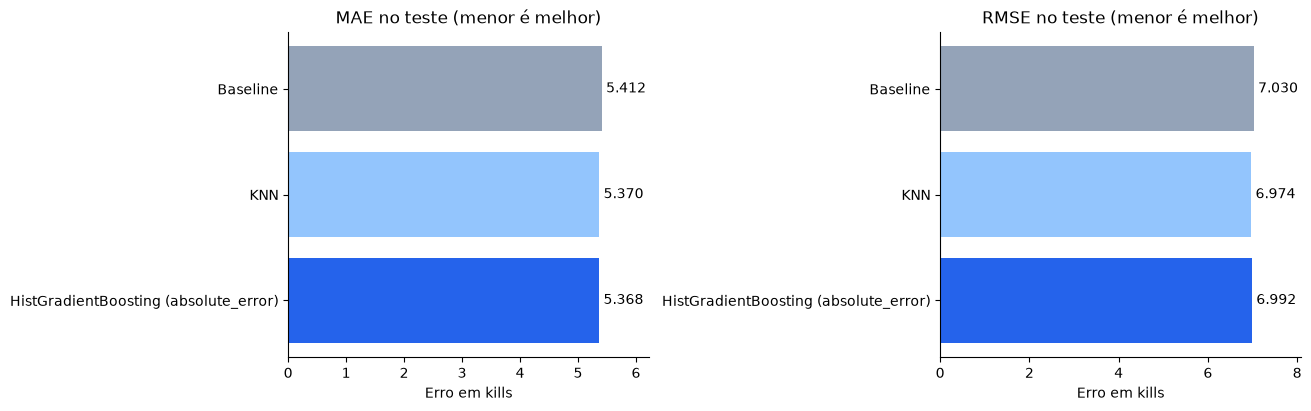

**HistGradientBoosting vs. baseline no teste:** redução de 0.045 kill no MAE (0.8%). MAE na validação 5.358 e no teste 5.368.

In [11]:
teste_hgb = dados['teste_hgb']
display(teste_hgb)

linha_baseline = teste_hgb.query("modelo == 'baseline_media'").iloc[0]
linha_hgb = teste_hgb.query("modelo == 'hist_gradient_boosting'").iloc[0]
linha_knn = teste_knn.query("modelo == 'knn'").iloc[0]
baseline_knn = teste_knn.query("modelo == 'baseline_media'").iloc[0]
# A baseline igual confirma que o HGB e o KNN foram avaliados nas mesmas partidas de teste.
if linha_baseline['partidas'] != baseline_knn['partidas'] or abs(
    linha_baseline['MAE'] - baseline_knn['MAE']
) > 1e-6:
    raise ValueError('A baseline do teste difere entre HistGradientBoosting e KNN: conjuntos de teste diferentes.')

comparacao_teste = pd.DataFrame([
    {'Método': 'Baseline', **linha_baseline[['MAE', 'RMSE', 'R2']]},
    {'Método': 'KNN', **linha_knn[['MAE', 'RMSE', 'R2']]},
    {'Método': f"HistGradientBoosting ({linha_hgb['loss']})", **linha_hgb[['MAE', 'RMSE', 'R2']]},
])
display(comparacao_teste.round(3))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
cores_teste = ['#94a3b8', '#93c5fd', '#2563eb']
for eixo, metrica in zip(eixos, ['MAE', 'RMSE']):
    barras = eixo.barh(comparacao_teste['Método'], comparacao_teste[metrica], color=cores_teste)
    eixo.invert_yaxis()
    eixo.bar_label(barras, fmt='%.3f', padding=3)
    eixo.set_xlim(0, comparacao_teste[metrica].max() * 1.15)
    eixo.set_title(f'{metrica} no teste (menor é melhor)')
    eixo.set_xlabel('Erro em kills')
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

mae_validacao_hgb = dados['hgb'].nsmallest(1, 'MAE').iloc[0]['MAE']
reducao = linha_baseline['MAE'] - linha_hgb['MAE']
display(Markdown(
    f'**HistGradientBoosting vs. baseline no teste:** redução de {reducao:.3f} kill no MAE '
    f"({reducao / linha_baseline['MAE']:.1%}). "
    f"MAE na validação {mae_validacao_hgb:.3f} e no teste {linha_hgb['MAE']:.3f}."
))

## HistGradientBoosting no teste: grid search x PSO

Compara no teste as duas configurações do HistGradientBoosting: a escolhida pela grid search e a encontrada pelo PSO. As duas foram escolhidas só com a validação, treinadas só no treino e avaliadas uma única vez nas mesmas partidas de teste. A baseline e o KNN aparecem como referência. Estes números **não** devem ser usados para escolher entre as duas buscas: a escolha do modelo final continua sendo feita na validação.

,conjunto,modelo,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,partidas,MAE,RMSE,R2
0,teste,baseline_media,NaN,NaN,NaN,NaN,NaN,NaN,25916,5.412317,7.030461,0.128914
1,teste,hist_gradient_boosting_pso,absolute_error,0.047094,201.0,9.0,293.0,1.579019,25916,5.362819,6.986395,0.139800


,Método,MAE_validacao,MAE_teste,RMSE_teste,R2_teste,diferenca_teste_validacao
0,Baseline,5.4109,5.4123,7.0305,0.1289,0.0015
1,KNN,5.3773,5.3695,6.9737,0.1429,-0.0077
2,HGB (grid search),5.3579,5.3678,6.9917,0.1385,0.0099
3,HGB (PSO),5.3558,5.3628,6.9864,0.1398,0.0070


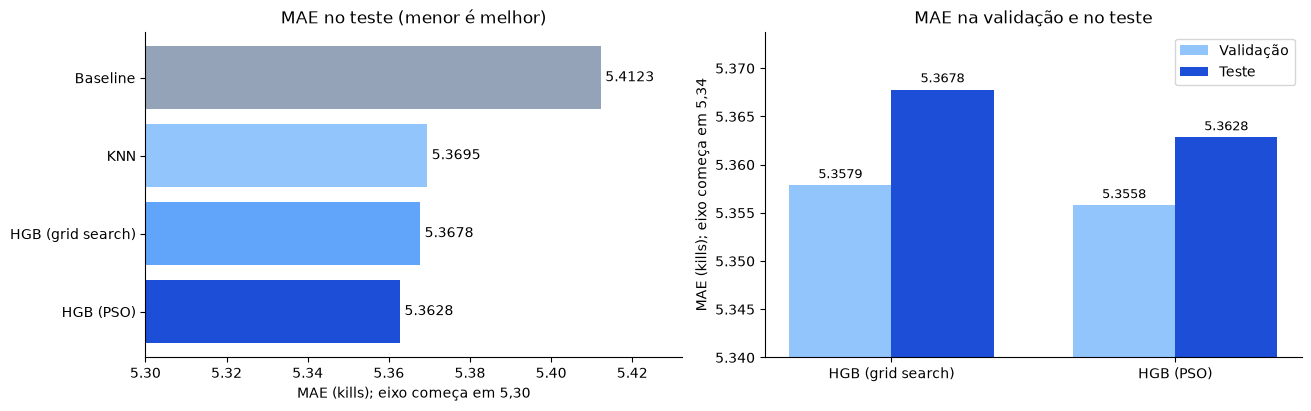

**PSO vs. grid search no teste:** MAE 5.3628 vs. 5.3678 (0.0050 kill a menos; 0.09%). Na validação, a diferença foi de 0.0021 kill.

In [12]:
teste_pso = dados['teste_hgb_pso']
display(teste_pso)

baseline_pso = teste_pso.query("modelo == 'baseline_media'").iloc[0]
linha_pso = teste_pso.query("modelo == 'hist_gradient_boosting_pso'").iloc[0]
# A baseline igual confirma que as duas buscas foram avaliadas nas mesmas partidas de teste.
if baseline_pso['partidas'] != linha_baseline['partidas'] or abs(
    baseline_pso['MAE'] - linha_baseline['MAE']
) > 1e-6:
    raise ValueError('A baseline do teste difere entre grid search e PSO: conjuntos de teste diferentes.')

mae_validacao_pso = dados['hgb_pso'].iloc[0]['MAE']
comparacao_buscas = pd.DataFrame([
    {'Método': 'Baseline', 'MAE_validacao': referencia, **linha_baseline[['MAE', 'RMSE', 'R2']]},
    {'Método': 'KNN', 'MAE_validacao': dados['knn'].iloc[0]['MAE'], **linha_knn[['MAE', 'RMSE', 'R2']]},
    {'Método': 'HGB (grid search)', 'MAE_validacao': mae_validacao_hgb,
     **linha_hgb[['MAE', 'RMSE', 'R2']]},
    {'Método': 'HGB (PSO)', 'MAE_validacao': mae_validacao_pso, **linha_pso[['MAE', 'RMSE', 'R2']]},
]).rename(columns={'MAE': 'MAE_teste', 'RMSE': 'RMSE_teste', 'R2': 'R2_teste'})
comparacao_buscas['diferenca_teste_validacao'] = (
    comparacao_buscas['MAE_teste'] - comparacao_buscas['MAE_validacao']
)
display(comparacao_buscas.round(4))

fig, (eixo_teste, eixo_val) = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
cores_buscas = ['#94a3b8', '#93c5fd', '#60a5fa', '#1d4ed8']
barras = eixo_teste.barh(comparacao_buscas['Método'], comparacao_buscas['MAE_teste'], color=cores_buscas)
eixo_teste.invert_yaxis()
eixo_teste.bar_label(barras, fmt='%.4f', padding=3)
eixo_teste.set_xlim(5.30, comparacao_buscas['MAE_teste'].max() + 0.02)
eixo_teste.set_title('MAE no teste (menor é melhor)')
eixo_teste.set_xlabel('MAE (kills); eixo começa em 5,30')

hgb = comparacao_buscas[comparacao_buscas['Método'].str.startswith('HGB')]
posicoes = range(len(hgb))
largura = 0.36
barras_val = eixo_val.bar([p - largura / 2 for p in posicoes], hgb['MAE_validacao'], largura,
                          label='Validação', color='#93c5fd')
barras_teste = eixo_val.bar([p + largura / 2 for p in posicoes], hgb['MAE_teste'], largura,
                            label='Teste', color='#1d4ed8')
eixo_val.set_xticks(list(posicoes), hgb['Método'])
eixo_val.bar_label(barras_val, fmt='%.4f', padding=3, fontsize=9)
eixo_val.bar_label(barras_teste, fmt='%.4f', padding=3, fontsize=9)
eixo_val.set_ylim(5.34, hgb[['MAE_validacao', 'MAE_teste']].to_numpy().max() + 0.006)
eixo_val.set_ylabel('MAE (kills); eixo começa em 5,34')
eixo_val.set_title('MAE na validação e no teste')
eixo_val.legend()
for eixo in (eixo_teste, eixo_val):
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

diferenca = linha_hgb['MAE'] - linha_pso['MAE']
display(Markdown(
    f"**PSO vs. grid search no teste:** MAE {linha_pso['MAE']:.4f} vs. {linha_hgb['MAE']:.4f} "
    f"({diferenca:.4f} kill a menos; {diferenca / linha_hgb['MAE']:.2%}). "
    f"Na validação, a diferença foi de {mae_validacao_hgb - mae_validacao_pso:.4f} kill."
))